# 🕵️‍♂️ Pakistani Social Media Content Detective
## Step 4: Recommendation engine: what should the brand post next?

This notebook turns the patterns from Steps 1–3 into a content plan for the channel. It looks at three things:
1. **Which kinds of video work best** (format, title style, guest, posting day), using views, engagement and the AI sentiment labels from Step 3.
2. **What viewers are asking for** in the comments (e.g. *"Please review the new MG HS Super Hybrid"*).
3. **What viewers care about and complain about**, so the next video answers it.

It then combines them into a ranked list of video ideas and a ready-to-use brief for the top one.

**Before you start:** `videos.csv` (Step 1) and `Step-3_comments_with_sentiment.csv` (Step 3) must be in this folder. No new packages are needed. Run the cells in order.

### Cell 1: Load the data (on Colab, select BOTH videos.csv and Step-3_comments_with_sentiment.csv)

In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)  # print wide tables on one line

# On Colab, upload the files. On your computer, they are read from this folder.
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    uploaded = files.upload()

videos = pd.read_csv("videos.csv")
comments = pd.read_csv("Step-3_comments_with_sentiment.csv")
print(f"Loaded {len(videos)} videos and {len(comments)} comments with sentiment")

Loaded 114 videos and 7915 comments with sentiment


### Cell 2: Settings (you can leave these as they are)

In [2]:
MIN_AGE_DAYS = 7   # videos younger than this are still collecting views, so we leave them out of comparisons
MIN_VIDEOS = 3     # a group needs at least this many videos before we compare it
TOP_IDEAS = 5      # how many video ideas to recommend
MIN_REQUESTS = 2   # a car needs at least this many separate requests to be recommended

### Cell 3: Describe each video
We read each title and tag the video with:
- **format**: owner review, first look, expert review, test drive, or a short teaser clip
- **title style**: does the title ask a question? Is it written in Roman Urdu? (same word list as Step 2)
- **celebrity owner**: a well-known guest shows their own car (add names to `CELEBRITIES` if you find more)
- **posting day and hour** in Pakistan time (UTC+5)

In [3]:
def video_format(title):
    t = title.lower()
    if re.search(r"quick review|goes live|go live|going live|will be live|live soon|live today|live tonight|stay tuned|visit now", t):
        return "Short / teaser"
    if re.search(r"owner|user review", t):
        return "Owner review"
    if re.search(r"first look", t):
        return "First look"
    if re.search(r"expert review", t):
        return "Expert review"
    if re.search(r"drive", t):
        return "Test drive"
    return "Other"

ROMAN_URDU_WORDS = {
    "hai", "hain", "hy", "nahi", "nhi", "bhai", "bhi", "kya", "kia", "yeh", "ye",
    "acha", "achi", "acchi", "bohat", "bahut", "bht", "mein", "se", "ko", "ka",
    "ki", "ke", "aur", "gari", "gaari", "gadi", "wala", "wali", "sahi", "kar",
    "karo", "tha", "thi", "aap", "ap", "apna", "koi", "kab", "kitni", "kitna",
    "kitne", "lakh", "lakhs", "hoga", "hogi", "chahiye", "zabardast", "mehngi",
    "sasti", "pakistan", "yar", "yaar", "jee", "ji", "kuch", "sab", "wo", "woh",
}
CELEBRITIES = ["ducky", "tabish", "zainab", "mustafa", "mishkat", "aadi khan"]

def is_roman_urdu(text):
    return any(w in ROMAN_URDU_WORDS for w in re.findall(r"[a-z]+", text.lower()))

videos["format"] = videos["title"].apply(video_format)
videos["question_title"] = videos["title"].str.contains("?", regex=False)
videos["roman_urdu_title"] = videos["title"].apply(is_roman_urdu)
videos["celebrity_owner"] = videos["title"].str.lower().str.contains("|".join(CELEBRITIES))

posted_pkt = pd.to_datetime(videos["published"]) + pd.Timedelta(hours=5)
videos["day"] = posted_pkt.dt.day_name()
videos["hour"] = posted_pkt.dt.hour

print(videos["format"].value_counts())
videos[["title", "format", "question_title", "roman_urdu_title", "celebrity_owner", "day", "hour"]].head(10)

format
Owner review      46
First look        33
Test drive        18
Short / teaser    13
Expert review      4
Name: count, dtype: int64


,title,format,question_title,roman_urdu_title,celebrity_owner,day,hour
0,iCAUR V27 | Test Drive Review Pakwheels,Test drive,False,False,False,Friday,19
1,"Chery Tiggo 8 PHEV | 11,000 KM Driven, EV Ran...",Owner review,False,False,False,Thursday,19
2,"BYD Atto 2 | 2026 Model, Comfort, Features & M...",Owner review,False,False,True,Wednesday,19
3,"Chery Tiggo 9 | 600+ HP, 20-Inch Rims & Real ...",Owner review,False,False,False,Tuesday,19
4,"Ducky Bhai Jetour T2 | Features, EV Range & Dr...",Owner review,False,True,True,Monday,20
5,Porsche 718 Boxster Owner’s Review | Cheapest ...,Owner review,True,True,False,Sunday,19
6,"Kaiyi e-Qute 04 Expert Review | Real Range, Ru...",Expert review,False,False,False,Saturday,20
7,Nora Metro & Neo | First Look Review | Pakwheels,First look,False,False,False,Friday,18
8,Suzuki FX 1988 | 20 KM/L & Under 5K Oil Change...,Owner review,False,False,False,Thursday,19
9,Honda Civic Rebirth | Real Fuel Average & Main...,Owner review,False,False,False,Wednesday,19


### Cell 4: Score each video
Three numbers per video:
- **views**: how many people it reached
- **engagement rate** = (likes + comments) ÷ views × 100: how many viewers bothered to react
- **comment mood** = % positive comments − % negative comments, using the AI labels from Step 3. Above 0 means viewers were mostly positive.

Views keep growing for days after a video is posted, so videos younger than `MIN_AGE_DAYS` are left out of the comparisons.

In [4]:
videos["engagement_rate"] = (videos["likes"] + videos["comment_count"]) / videos["views"] * 100

mood = comments.groupby("video_id")["sentiment"].value_counts(normalize=True).unstack(fill_value=0) * 100
mood["comment_mood"] = mood["positive"] - mood["negative"]
videos = videos.merge(mood[["comment_mood"]], left_on="video_id", right_index=True, how="left")

# Views were counted when Step 1 ran; the newest comment tells us roughly when that was
collected = pd.to_datetime(comments["published"]).max()
videos["age_days"] = (collected - pd.to_datetime(videos["published"])).dt.days
mature = videos[videos["age_days"] >= MIN_AGE_DAYS]
full_videos = mature[mature["format"] != "Short / teaser"]

CHANNEL = {
    "views": mature["views"].median(),
    "engagement_rate": mature["engagement_rate"].median(),
    "comment_mood": mature["comment_mood"].mean(),
}
print(f"Data collected around {collected:%d %b %Y}. Using {len(mature)} of {len(videos)} videos (at least {MIN_AGE_DAYS} days old).")
print(f"A typical video: {CHANNEL['views']:,.0f} views, {CHANNEL['engagement_rate']:.2f}% engagement, comment mood {CHANNEL['comment_mood']:+.1f}")

Data collected around 24 Oct 2026. Using 107 of 114 videos (at least 7 days old).
A typical video: 92,208 views, 1.59% engagement, comment mood -6.6


### Cell 5: Which kind of video works best?
For each group of videos we compare it with a typical video on the channel and combine the three numbers into one **performance score**:

`score = (views ÷ typical views + engagement ÷ typical engagement + (100 + mood) ÷ (100 + typical mood)) ÷ 3`

**1.00 = a typical video.** 1.20 means about 20% better than typical. Short teaser clips are left out of the title and guest comparisons, because they get far fewer views by design.

By format:
                videos  median_views  engagement_rate  comment_mood  score
format                                                                    
Owner review        41       95338.0             1.54          0.89   1.03
Short / teaser      13       30136.0             2.48          4.36   1.00
First look          33      134708.0             0.93        -17.06   0.98
Expert review        3      107377.0             0.84          2.63   0.93
Test drive          17       47683.0             2.13        -14.33   0.92

Title and guest (full-length videos only):
                       videos_with  views_with  views_without  score_with  score_without
feature                                                                                 
Title asks a question           35    100840.0        84334.0        1.00           0.86
Title in Roman Urdu             33    133319.0        91506.0        1.13           0.90
Celebrity owner                  4    176816.5        94389.0   

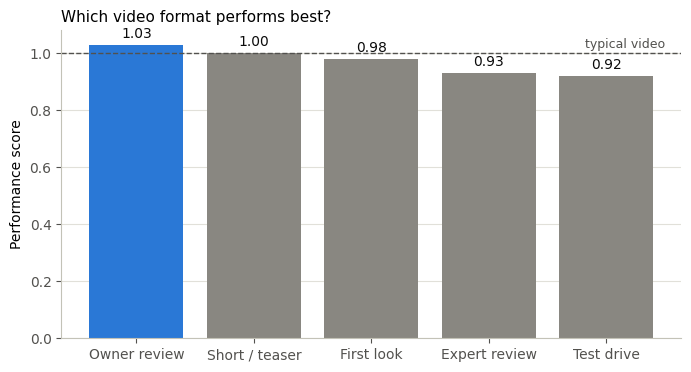

In [5]:
def compare(data, column):
    table = data.groupby(column).agg(
        videos=("video_id", "size"),
        median_views=("views", "median"),
        engagement_rate=("engagement_rate", "median"),
        comment_mood=("comment_mood", "mean"),
    )
    table = table[table["videos"] >= MIN_VIDEOS]
    table["score"] = (
        table["median_views"] / CHANNEL["views"]
        + table["engagement_rate"] / CHANNEL["engagement_rate"]
        + (100 + table["comment_mood"]) / (100 + CHANNEL["comment_mood"])
    ) / 3
    return table.sort_values("score", ascending=False).round(2)

by_format = compare(mature, "format")
print("By format:")
print(by_format)

STYLE_FEATURES = {
    "question_title": "Title asks a question",
    "roman_urdu_title": "Title in Roman Urdu",
    "celebrity_owner": "Celebrity owner",
}
rows = []
for column, name in STYLE_FEATURES.items():
    t = compare(full_videos, column)
    if True in t.index and False in t.index:
        rows.append({
            "feature": name,
            "videos_with": t.loc[True, "videos"],
            "views_with": t.loc[True, "median_views"],
            "views_without": t.loc[False, "median_views"],
            "score_with": t.loc[True, "score"],
            "score_without": t.loc[False, "score"],
        })
by_style = pd.DataFrame(rows).set_index("feature")
print("\nTitle and guest (full-length videos only):")
print(by_style)

colors = ["#2a78d6" if i == 0 else "#898781" for i in range(len(by_format))]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(by_format.index, by_format["score"], color=colors)
ax.bar_label(bars, fmt="%.2f", padding=3, color="#0b0b0b")
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--")
ax.text(len(by_format) - 0.5, 1.01, "typical video", ha="right", va="bottom", color="#52514e", fontsize=9)
ax.set_ylabel("Performance score")
ax.set_title("Which video format performs best?", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.set_axisbelow(True)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
plt.show()

### Cell 6: Best day and time to post
Each day only has around 15 videos, so treat this as a hint, not a rule. For the hour we only compare hours with 10 or more videos, because most videos go out in the evening.

In [6]:
by_day = compare(full_videos, "day")
print(by_day)
best_day = by_day.index[0]

# Only hours with plenty of videos, so one lucky video can't decide it
by_hour = compare(full_videos, "hour")
by_hour = by_hour[by_hour["videos"] >= 10]
best_hour = by_hour.index[0]
print("\nBy posting hour (Pakistan time), hours with 10+ videos:")
print(by_hour)
print(f"\nBest day: {best_day}. Best time: around {best_hour}:00 PKT.")

           videos  median_views  engagement_rate  comment_mood  score
day                                                                  
Tuesday         7      143105.0             1.17          9.82   1.15
Wednesday      14      100217.0             1.49         -3.70   1.02
Friday         11      129853.0             0.93        -10.26   0.99
Saturday       19       92817.0             1.09         -8.58   0.89
Monday         15       63115.0             1.61        -10.32   0.88
Sunday         15       55608.0             1.72        -11.81   0.87
Thursday       13       96915.0             0.99        -13.18   0.87

By posting hour (Pakistan time), hours with 10+ videos:
      videos  median_views  engagement_rate  comment_mood  score
hour                                                            
20        19      133319.0             1.25         -6.67   1.08
18        18      100097.0             1.53         -1.65   1.03
19        32       94284.0             1.33         -

### Cell 7: What are viewers asking for?
We find **request comments**: short comments (30 words or fewer) that contain a request word (*please, plz, kindly, karo, krain, banao…*) **and** a video word (*review, video, compare, vs*). Then we look for car names in them.

- **demand** = number of requests + 1 point for every 10 likes on those requests (likes mean other viewers want it too)
- **asked_for** = the format viewers named (expert review, owner review…)
- **already_on_channel** = videos about that car in our data, and their formats

Only cars with at least `MIN_REQUESTS` separate requests are recommended, so one popular comment can't decide the plan on its own.

If a car is missing from `CAR_NAMES`, add it with a pattern that matches how people write it.

Found 136 request comments


35 cars requested; 17 of them by at least 2 different comments
                    requests  likes                    asked_for  demand        already_on_channel
car                                                                                               
MG HS Super Hybrid         8     13  Expert review, Owner review     9.3                      none
Chery Tiggo 9              4     44    Expert review, Comparison     8.4              Owner review
Jaecoo J5                  5     29  Expert review, Owner review     7.9  Owner review, Test drive
BYD Atto 2                 4     12  Expert review, Owner review     5.2              Owner review
Jaecoo J7                  3      6     Comparison, Owner review     3.6              Owner review
MG ZS Hybrid+              3      2    Expert review, Comparison     3.2    First look, Test drive
Haval H6                   3      0                                  3.0                First look
Suzuki Swift               2      4           

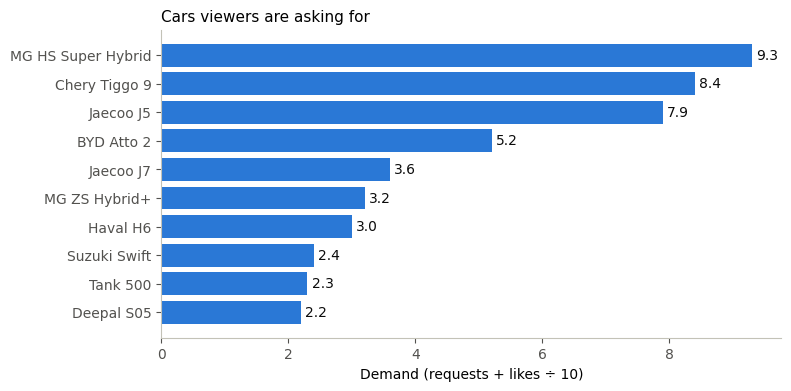

In [7]:
CAR_NAMES = {
    "MG HS Super Hybrid": r"\bhs ?(?:super ?)?hybrid|\bmg ?hs\b(?! ?phev)", "MG HS PHEV": r"\bhs ?phev",
    "MG ZS Hybrid+": r"\bmg ?zs\b", "MG U9": r"\bu9\b", "MG Binguo": r"binguo", "MG Cyberster": r"cyberster",
    "Jaecoo J5": r"\bj5\b", "Jaecoo J7": r"\bj7\b", "Omoda 7": r"\bomoda\b",
    "Chery Tiggo 4": r"tiggo ?4", "Chery Tiggo 7": r"tiggo ?7", "Chery Tiggo 8": r"tiggo ?8", "Chery Tiggo 9": r"tiggo ?9",
    "Chery QQ3": r"\bqq ?3\b", "Lepas": r"\blepas\b",
    "Deepal S05": r"\bdeepal\b|\bs ?05\b", "Deepal S07": r"\bs ?07\b",
    "Haval H6": r"\bh ?6\b", "Haval H7": r"\bh ?7\b", "Haval Jolion": r"jolion",
    "Tank 300": r"tank ?300", "Tank 500": r"tank ?500", "GWM Cannon": r"cannon|\bp ?[35]00\b", "GWM ORA": r"\bora ?\d?\b",
    "BYD Atto 2": r"atto ?2", "BYD Atto 3": r"atto ?3", "BYD Seal": r"\bseal\b", "BYD Sealion": r"sealion", "BYD Shark": r"\bshark\b",
    "Changan Oshan X7": r"oshan", "Changan Alsvin": r"alsvin", "Avatr": r"avatr", "Changan Nevo": r"\bnevo\b",
    "Jetour": r"jetour", "Kaiyi": r"kaiyi|e-? ?qute", "Nora EV": r"\bnora\b", "Honri VE": r"honri",
    "XPeng": r"xpeng|\bl ?03\b", "Arcfox": r"arcfox", "iCAUR": r"icaur|\bv ?2[37]\b", "GAC Aion": r"\baion\b",
    "Toyota Corolla": r"corolla(?! ?cross)", "Toyota Corolla Cross": r"corolla ?cross", "Toyota Yaris": r"yaris",
    "Toyota Fortuner": r"fortuner", "Toyota Land Cruiser": r"land ?cruiser|\blc ?(?:70|80|200|300)\b", "Toyota Hilux": r"hilux|\brevo\b",
    "Toyota Prado": r"prado", "Toyota C-HR": r"\bc-? ?hr\b", "Toyota Camry": r"camry",
    "Honda Civic": r"civic", "Honda City": r"honda city", "Honda HR-V": r"\bhr-? ?v\b", "Honda BR-V": r"\bbr-? ?v\b",
    "Honda CR-V": r"\bcr-? ?v\b", "Honda Vezel": r"vezel",
    "Suzuki Alto": r"\balto\b", "Suzuki Cultus": r"cultus", "Suzuki Swift": r"swift", "Suzuki Wagon R": r"wagon ?r\b",
    "Suzuki Jimny": r"jimny", "Suzuki Fronx": r"fronx",
    "Kia Sportage": r"sportage", "Kia Stonic": r"stonic", "Kia Sorento": r"sorento", "Kia Picanto": r"picanto",
    "Hyundai Tucson": r"tucson", "Hyundai Elantra": r"elan?tra|elentra", "Hyundai Sonata": r"sonata",
    "Hyundai Santa Fe": r"santa ?fe", "Hyundai Palisade": r"palisade",
    "Isuzu D-Max": r"d-? ?max", "Peugeot 2008": r"peugeot", "Proton": r"proton|\bsaga\b", "Nissan Serena": r"serena",
}
ASKED_FORMATS = {
    "Expert review": r"expert",
    "Owner review": r"owner|user",
    "First look": r"first look",
    "Comparison": r"compar|\bvs\b",
    "Test drive": r"drive",
}
REQUEST_WORDS = r"\b(?:please|plz|pls|plzz|kindly|request|we want|we need|bring|make|karo|kro|kren|krein|krain|karain|karein|kijiye|banao|bnao|banayen|bnayen|bnaya|banaya|kab aye|kab ayega|do a|do an|do the)\b"
VIDEO_WORDS = r"\b(?:review|reviews|video|comparison|compare|vs)\b"

text = comments["comment"].str.lower()
short = text.str.split().str.len() <= 30
comments["is_request"] = short & text.str.contains(REQUEST_WORDS) & text.str.contains(VIDEO_WORDS)
requests = comments[comments["is_request"]]
print(f"Found {len(requests)} request comments")

rows = []
for _, r in requests.iterrows():
    low = r["comment"].lower()
    asked = next((f for f, pattern in ASKED_FORMATS.items() if re.search(pattern, low)), None)
    for car, pattern in CAR_NAMES.items():
        if re.search(pattern, low):
            rows.append({"car": car, "likes": r["comment_likes"], "asked_for": asked, "comment": r["comment"]})
car_requests = pd.DataFrame(rows)

def most_asked(formats):
    counts = formats.dropna().value_counts()
    order = sorted(counts.index, key=lambda f: (-counts[f], list(ASKED_FORMATS).index(f)))
    return ", ".join(order)

def formats_on_channel(car):
    titles = videos[videos["title"].str.lower().str.contains(CAR_NAMES[car])]
    return sorted(set(titles["format"]) - {"Short / teaser"})

demand = car_requests.groupby("car").agg(
    requests=("comment", "size"),
    likes=("likes", "sum"),
    asked_for=("asked_for", most_asked),
)
demand["demand"] = demand["requests"] + demand["likes"] / 10
demand["already_on_channel"] = [", ".join(formats_on_channel(car)) or "none" for car in demand.index]
demand = demand.sort_values("demand", ascending=False).round(1)
print(f"{len(demand)} cars requested; {(demand['requests'] >= MIN_REQUESTS).sum()} of them by at least {MIN_REQUESTS} different comments")
demand = demand[demand["requests"] >= MIN_REQUESTS]
print(demand.head(10))

top = demand.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(top.index, top["demand"], color="#2a78d6")
ax.bar_label(bars, fmt="%.1f", padding=3, color="#0b0b0b")
ax.set_xlabel("Demand (requests + likes ÷ 10)")
ax.set_title("Cars viewers are asking for", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
plt.show()

### Cell 8: What do viewers care about?
We tag every comment with topics using keyword lists (English and Roman Urdu), then use the AI sentiment from Step 3 to see how viewers feel about each topic. A topic that is more negative than comments overall is a **concern**. Concerns are ranked by how many negative comments they have, and the top ones are what the next video should tackle head-on.

In [8]:
TOPICS = {
    "Price & value": (
        r"price|qeemat|keemat|qimat|mehng|mehang|costly|expensive|over ?priced|value for money|worth|lakh|\blacs?\b|crore|\bcr\b|million|\btax",
        "state the on-road price with taxes and compare it with rivals at the same price",
    ),
    "Fuel average & range": (
        r"average|\bavg\b|mileage|km/l|kmpl|\brange\b|fuel|petrol|battery|charging|charger",
        "test the real fuel average or EV range on the road, not the brochure figure",
    ),
    "Features & interior": (
        r"feature|sunroof|screen|adas|\bseats?\b|interior|infotainment|carplay|airbag",
        "go through the features, including what is missing compared with other markets",
    ),
    "Looks & design": (
        r"\blooks?\b|design|ugly|beautiful|stylish|\bshape\b|colou?r|khoobsurat|khubsurat",
        "show the car clearly from every angle, in a popular colour",
    ),
    "After-sales, parts & resale": (
        r"after ?sales?|\bparts\b|spare|service|resale|depreciation|dealer|warranty|maintenance|reliab",
        "cover after-sales service, parts availability and resale value",
    ),
    "Presenter & video": (
        r"suneel|sunil|manj|munj|presenter|\bhost\b|anchor|camera ?man|\bvoice\b|audio|editing|music|urdu|english|thumbnail",
        "keep a real host's voice (no AI voice-over), speak in Urdu and keep it focused",
    ),
    "Trust (paid or biased)": (
        r"\bpaid\b|sponsor|commission|biased|khilaya|khilaye|pes[ae] diye|paise diye|advertis|promot",
        "say clearly whether the video is sponsored, and show the cons as well as the pros",
    ),
}

rows = []
for topic, (pattern, advice) in TOPICS.items():
    about = comments[text.str.contains(pattern)]
    share = about["sentiment"].value_counts(normalize=True) * 100
    rows.append({
        "topic": topic,
        "comments": len(about),
        "%_of_all": round(len(about) / len(comments) * 100, 1),
        "%_negative": round(share.get("negative", 0), 1),
        "%_positive": round(share.get("positive", 0), 1),
        "advice": advice,
    })
topics = pd.DataFrame(rows).set_index("topic")
topics["mood"] = topics["%_positive"] - topics["%_negative"]
topics = topics.sort_values("comments", ascending=False)
print(topics.drop(columns="advice"))

# Concerns = topics more negative than comments overall, biggest pile of negative comments first
overall_mood = (comments["sentiment"] == "positive").mean() * 100 - (comments["sentiment"] == "negative").mean() * 100
topics["negative_comments"] = (topics["comments"] * topics["%_negative"] / 100).round().astype(int)
concerns = topics[(topics["%_of_all"] >= 1) & (topics["mood"] < overall_mood)].sort_values("negative_comments", ascending=False)
print(f"\nOverall comment mood: {overall_mood:+.1f}. Topics more negative than that:")
print(concerns[["comments", "negative_comments", "mood"]])

                             comments  %_of_all  %_negative  %_positive  mood
topic                                                                        
Price & value                    1074      13.6        39.4        19.6 -19.8
Presenter & video                 776       9.8        51.8        26.7 -25.1
Looks & design                    629       7.9        38.5        41.7   3.2
Fuel average & range              542       6.8        38.9        19.0 -19.9
Features & interior               361       4.6        44.9        26.9 -18.0
After-sales, parts & resale       238       3.0        50.0        21.4 -28.6
Trust (paid or biased)            150       1.9        60.0        16.7 -43.3

Overall comment mood: -7.6. Topics more negative than that:
                             comments  negative_comments  mood
topic                                                         
Price & value                    1074                423 -19.8
Presenter & video                 776           

### Cell 9: The recommendation: what to post next
This cell puts everything together:
- **What**: the cars with the highest viewer demand (Cell 7), in the format viewers asked for. If they didn't say, or the channel has already made that format for this car, it picks the best-scoring format (Cell 5) the channel hasn't made yet.
- **How**: the title style, guest and posting day that scored best (Cells 5–6).
- **What to cover**: the concerns with the most negative comments (Cell 8).

It prints a brief and saves the ranked ideas to `Step-4_recommendations.csv`.

In [9]:
full_formats = [f for f in by_format.index if f != "Short / teaser"]
best_format = full_formats[0]

def pick_format(car):
    done = formats_on_channel(car)
    asked = [f for f in demand.loc[car, "asked_for"].split(", ") if f]
    for f in asked + full_formats:
        if f not in done:
            return f
    return best_format

question_helps = by_style.loc["Title asks a question", "score_with"] > by_style.loc["Title asks a question", "score_without"]
urdu_helps = by_style.loc["Title in Roman Urdu", "score_with"] > by_style.loc["Title in Roman Urdu", "score_without"]
if question_helps and urdu_helps:
    hook = "Kya Yeh Worth Buying Hai?"
elif question_helps:
    hook = "Is It Worth Buying?"
else:
    hook = "Full Details"

ideas = []
for car in demand.head(TOP_IDEAS).index:
    row = demand.loc[car]
    fmt = pick_format(car)
    asks = car_requests[car_requests["car"] == car].sort_values("likes", ascending=False)
    same_format = asks[asks["asked_for"] == fmt]
    example = (same_format if len(same_format) else asks).iloc[0]["comment"]
    ideas.append({
        "rank": len(ideas) + 1,
        "video_idea": f"{car} | {fmt}",
        "suggested_title": f"{car} {fmt.title()} | {hook}",
        "why": f"{row['requests']} viewer requests ({row['likes']} likes); on channel already: {row['already_on_channel']}",
        "example_request": example,
        "post_on": f"{best_day}, around {best_hour}:00 PKT",
        "cover": "; ".join(concerns["advice"].head(3)),
    })
plan = pd.DataFrame(ideas).set_index("rank")
plan.to_csv("Step-4_recommendations.csv", encoding="utf-8-sig")
if IN_COLAB:
    files.download("Step-4_recommendations.csv")

celeb = by_style.loc["Celebrity owner"] if "Celebrity owner" in by_style.index else None
top_idea = plan.iloc[0]
print("=" * 70)
print("WHAT TO POST NEXT")
print("=" * 70)
for rank, idea in plan.iterrows():
    print(f"{rank}. {idea['video_idea']}")
    print(f"   why: {idea['why']}")
    print(f"   e.g. \"{idea['example_request'][:110]}\"")
print()
print("HOW TO POST IT")
print(f"- Format that performs best overall: {best_format} (score {by_format.loc[best_format, 'score']:.2f}; 1.00 = typical video)")
print(f"- Title: {'ask a question' if question_helps else 'state the topic plainly'}"
      f"{' in Roman Urdu' if urdu_helps else ''}, e.g. \"{top_idea['suggested_title']}\"")
if celeb is not None and celeb["score_with"] > celeb["score_without"]:
    print(f"- Guest: celebrity owners got {celeb['views_with']:,.0f} median views vs {celeb['views_without']:,.0f} "
          f"(only {int(celeb['videos_with'])} videos, so worth testing rather than certain)")
print(f"- When: {top_idea['post_on']}")
print()
print("WHAT TO COVER (topics with the most negative comments)")
for topic, t in concerns.iterrows():
    print(f"- {topic} ({t['negative_comments']} negative comments, mood {t['mood']:+.0f}): {t['advice']}")
print()
print("Saved Step-4_recommendations.csv")
plan

WHAT TO POST NEXT
1. MG HS Super Hybrid | Expert review
   why: 8 viewer requests (13 likes); on channel already: none
   e.g. "17:23 MAKE expert review of that MG HS Super hybrid"
2. Chery Tiggo 9 | Expert review
   why: 4 viewer requests (44 likes); on channel already: Owner review
   e.g. "We want Chery Tiggo 9 PHEV Expert review by Suneel Munj very soon ❤"
3. Jaecoo J5 | Expert review
   why: 5 viewer requests (29 likes); on channel already: Owner review, Test drive
   e.g. "Do expert review of jaecoo j5 please, it will clear lots of doubts about overall the brand"
4. BYD Atto 2 | Expert review
   why: 4 viewer requests (12 likes); on channel already: Owner review
   e.g. "make expert review for byd atto 2"
5. Jaecoo J7 | Comparison
   why: 3 viewer requests (6 likes); on channel already: Owner review
   e.g. "Please compare it with jaecoo j7 phev Which one is best ? Opinion needed in the comment section please"

HOW TO POST IT
- Format that performs best overall: Owner review (sco

,video_idea,suggested_title,why,example_request,post_on,cover
rank,,,,,,
1,MG HS Super Hybrid | Expert review,MG HS Super Hybrid Expert Review | Kya Yeh Wor...,8 viewer requests (13 likes); on channel alrea...,17:23 MAKE expert review of that MG HS Super h...,"Tuesday, around 20:00 PKT",state the on-road price with taxes and compare...
2,Chery Tiggo 9 | Expert review,Chery Tiggo 9 Expert Review | Kya Yeh Worth Bu...,4 viewer requests (44 likes); on channel alrea...,We want Chery Tiggo 9 PHEV Expert review by Su...,"Tuesday, around 20:00 PKT",state the on-road price with taxes and compare...
3,Jaecoo J5 | Expert review,Jaecoo J5 Expert Review | Kya Yeh Worth Buying...,5 viewer requests (29 likes); on channel alrea...,"Do expert review of jaecoo j5 please, it will ...","Tuesday, around 20:00 PKT",state the on-road price with taxes and compare...
4,BYD Atto 2 | Expert review,BYD Atto 2 Expert Review | Kya Yeh Worth Buyin...,4 viewer requests (12 likes); on channel alrea...,make expert review for byd atto 2,"Tuesday, around 20:00 PKT",state the on-road price with taxes and compare...
5,Jaecoo J7 | Comparison,Jaecoo J7 Comparison | Kya Yeh Worth Buying Hai?,3 viewer requests (6 likes); on channel alread...,Please compare it with jaecoo j7 phev Which on...,"Tuesday, around 20:00 PKT",state the on-road price with taxes and compare...
